# Session 51 Solutions: Project Review Workshop

Data Science with Python, Level 3, Stage 8: Capstone

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"

## In-Class Exercises

### In-Class Exercise 1: Refactor a Messy Cell

In [2]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
def pass_rate_by(df, column, bins):
    groups = pd.cut(df[column], bins)
    return df.groupby(groups, observed=True)["passed"].mean().round(2)

print(pass_rate_by(exams, "study_hours_week", 4))
print(pass_rate_by(exams, "sleep_hours", 4))

study_hours_week
(0.278, 5.9]    0.27
(5.9, 11.5]     0.53
(11.5, 17.1]    0.87
(17.1, 22.7]    1.00
Name: passed, dtype: float64
sleep_hours
(3.994, 5.5]    0.36
(5.5, 7.0]      0.38
(7.0, 8.5]      0.52
(8.5, 10.0]     0.52
Name: passed, dtype: float64


### In-Class Exercise 2: Write Three Tests

In [3]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
features = ["class", "study_hours_week", "sleep_hours", "attendance_pct"]
prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["class"]), ("num", StandardScaler(), features[1:])])
model = Pipeline([("prep", prep), ("model", LogisticRegression())]).fit(exams[features], exams["passed"])

def pass_probability(model, class_name, study, sleep, attendance):
    row = pd.DataFrame([{"class": class_name, "study_hours_week": study, "sleep_hours": sleep, "attendance_pct": attendance}])
    return float(model.predict_proba(row)[0, 1])

p = pass_probability(model, "B", 5, 7, 85)
assert 0 <= p <= 1
assert pass_probability(model, "B", 15, 8, 98) > pass_probability(model, "B", 1, 5, 65)
assert isinstance(p, float)
print("All tests passed")

All tests passed


### In-Class Exercise 3: Errors by Group

In [4]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
features = ["class", "study_hours_week", "sleep_hours", "attendance_pct"]
prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["class"]), ("num", StandardScaler(), features[1:])])
model = Pipeline([("prep", prep), ("model", LogisticRegression())])
oof = cross_val_predict(model, exams[features], exams["passed"], cv=5, method="predict_proba")[:, 1]
wrong = (oof >= 0.5) != exams["passed"]
print(wrong.groupby(exams["class"]).mean().round(2))
print(wrong.groupby(pd.cut(exams["sleep_hours"], [3, 6, 7, 8, 11]), observed=True).mean().round(2))

class
A    0.42
B    0.34
C    0.29
D    0.25
E    0.30
Name: passed, dtype: float64
sleep_hours
(3, 6]     0.30
(6, 7]     0.26
(7, 8]     0.34
(8, 11]    0.36
Name: passed, dtype: float64


### In-Class Exercise 4: Swap and Review

In [5]:
# Strength: a clear one-sentence pitch and a working app.
# Problem 1: the notebook fails at cell 14 after a restart (a variable defined later). Fix: move the cell up.
# Problem 2: the test set is used to choose the threshold. Fix: use cross_val_predict on the development set.
# Problem 3: the app accepts negative ages. Fix: set min_value=0 on the number input.
print("Review written")

Review written


## Part A: Basic

### Exercise 1: Step 1: Run the Checklist

In [6]:
status = {
    "Question": "done", "Data": "done", "Model": "partly", "Evaluation": "missing",
    "Code": "partly", "App": "partly", "README": "missing",
}
for area, s in status.items():
    print(f"{area:11} {s}")
print("Fix today:", [a for a, s in status.items() if s != "done"])

Question    done
Data        done
Model       partly
Evaluation  missing
Code        partly
App         partly
README      missing
Fix today: ['Model', 'Evaluation', 'Code', 'App', 'README']


### Exercise 2: Step 2: Constants and Functions

In [7]:
FEATURES = ["class", "study_hours_week", "sleep_hours", "attendance_pct"]
TARGET, SEED, TEST_SIZE = "passed", 0, 0.2

def load_data():
    return pd.read_csv(DATA_URL + "exam_scores.csv")

def build_model(C=1.0):
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["class"]), ("num", StandardScaler(), FEATURES[1:])])
    return Pipeline([("prep", prep), ("model", LogisticRegression(C=C))])

def evaluate(model, X, y):
    s = cross_val_score(model, X, y, cv=5, scoring="roc_auc")
    return f"AUC {s.mean():.3f} +/- {s.std():.3f}"

df = load_data()
X_dev, X_test, y_dev, y_test = train_test_split(df[FEATURES], df[TARGET], test_size=TEST_SIZE, stratify=df[TARGET], random_state=SEED)
for C in [0.1, 1, 10]:
    print(C, evaluate(build_model(C), X_dev, y_dev))

0.1 AUC 0.721 +/- 0.036
1 AUC 0.716 +/- 0.036
10 AUC 0.716 +/- 0.036


## Part B: Intermediate

### Exercise 3: Step 3: Tests for the App Function

Column 0 of `predict_proba` is the probability of the first class, here `False` (failing), which is what a teacher's app should show.

In [8]:
df = pd.read_csv(DATA_URL + "exam_scores.csv")
features = ["class", "study_hours_week", "sleep_hours", "attendance_pct"]
prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["class"]), ("num", StandardScaler(), features[1:])])
model = Pipeline([("prep", prep), ("model", LogisticRegression())]).fit(df[features], df["passed"])

def validate(study, sleep, attendance):
    problems = []
    if not 0 <= study <= 60:
        problems.append("Study hours must be 0 to 60.")
    if not 0 <= sleep <= 14:
        problems.append("Sleep must be 0 to 14 hours.")
    if not 0 <= attendance <= 100:
        problems.append("Attendance must be 0 to 100 percent.")
    return problems

def risk_of_failing(class_name, study, sleep, attendance):
    row = pd.DataFrame([{"class": class_name, "study_hours_week": study, "sleep_hours": sleep, "attendance_pct": attendance}])
    return float(model.predict_proba(row)[0, 0])

r = risk_of_failing("A", 5, 7, 85)
assert 0 <= r <= 1
assert risk_of_failing("A", 1, 7, 85) > risk_of_failing("A", 15, 7, 85)
assert validate(-3, 7, 85) != []
assert validate(5, 7, 85) == []
print("All app tests passed")

All app tests passed


### Exercise 4: Step 4: Error Analysis

In [9]:
df = pd.read_csv(DATA_URL + "exam_scores.csv")
features = ["class", "study_hours_week", "sleep_hours", "attendance_pct"]
prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["class"]), ("num", StandardScaler(), features[1:])])
model = Pipeline([("prep", prep), ("model", LogisticRegression())])
oof = cross_val_predict(model, df[features], df["passed"], cv=5, method="predict_proba")[:, 1]
wrong = pd.Series((oof >= 0.5) != df["passed"], index=df.index)
by_band = wrong.groupby(pd.cut(df["study_hours_week"], [0, 3, 6, 10, 30]), observed=True).mean()
print(by_band.round(2).sort_values(ascending=False).head(2))
# Students in the middle study range are hardest to call. Earlier test results or homework marks
# would likely help separate them.

study_hours_week
(6, 10]    0.47
(3, 6]     0.32
Name: passed, dtype: float64


## Part C: Challenge

### Exercise 5: Step 5: A Model Comparison Chart

The numbers here are an example; use your own cross-validated results. Highlighting one bar tells the audience where to look.

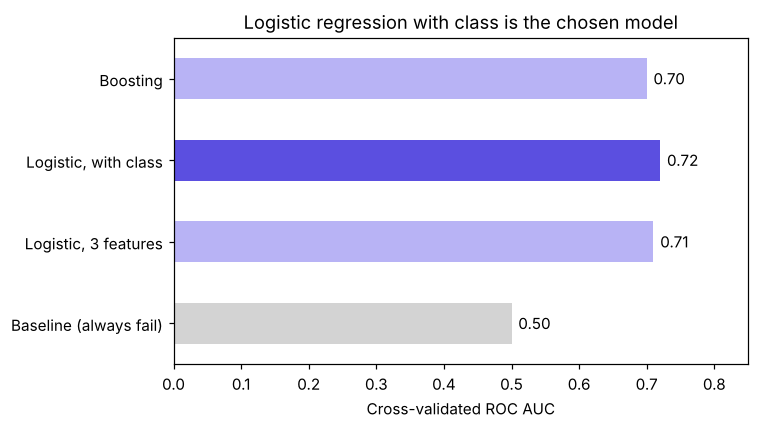

In [10]:
results = pd.Series({"Baseline (always fail)": 0.50, "Logistic, 3 features": 0.71, "Logistic, with class": 0.72, "Boosting": 0.70})
colors = ["lightgrey", "#b8b3f5", "#5b4fe0", "#b8b3f5"]
ax = results.plot(kind="barh", color=colors)
for i, v in enumerate(results):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center")
ax.set_xlim(0, 0.85)
ax.set_xlabel("Cross-validated ROC AUC")
ax.set_title("Logistic regression with class is the chosen model")
plt.tight_layout()
plt.show()

## Part D: Cumulative Project

### Exercise 6: Step 6: Fix, Commit, Redeploy

In [11]:
commits = [
    "Move threshold choice to out-of-fold predictions",
    "Reject negative ages in the app inputs",
    "Fix notebook order so it runs after a restart",
]
for c in commits:
    print("-", c)

- Move threshold choice to out-of-fold predictions
- Reject negative ages in the app inputs
- Fix notebook order so it runs after a restart


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | assert only acts when the condition is False. |
| 2 | B | No hunting for magic numbers. |
| 3 | B | Nonsense predictions usually mean a bug. |
| 4 | B | Averages hide unequal performance. |
| 5 | C | Specific place, problem and fix. |